# Etapa 2 — Análise Exploratória de Dados

Entrada: os CSVs que a Etapa 1 gravou em `../data/raw/`.
Saída: uma tabela horária limpa em `../data/processed/dataset.csv`, mais os
gráficos e as conclusões que sustentam o que você vai afirmar.

As seções abaixo são um roteiro, não uma receita. Responda as perguntas de
cada uma com código e, no fim, em texto. Acrescente seções se quiser.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

DIR_RAW = Path("..") / "data" / "raw"
DIR_PROC = Path("..") / "data" / "processed"
DIR_PROC.mkdir(parents=True, exist_ok=True)

## 1. Carregar os CSVs

Leia os quatro arquivos de `../data/raw/`.

- Quantas linhas tem cada um? O número faz sentido para o período coletado?
- Os tipos vieram certos, ou datas e números chegaram como texto?
- Há colunas vazias, ou linhas duplicadas?

In [2]:
mares_ano = pd.read_csv(DIR_RAW / "mares_2026.csv")
mares_2025 = pd.read_csv(DIR_RAW / "mares_2025.csv")
mares_mes = pd.read_csv(DIR_RAW / "mares_previsao.csv")
ondas = pd.read_csv(DIR_RAW / "ondas.csv")
vento = pd.read_csv(DIR_RAW / "vento.csv")

tabelas = {"mares_2025": mares_2025, "mares_2026": mares_ano, "mares_previsao": mares_mes, "ondas": ondas, "vento": vento}
for nome, df in tabelas.items():
    print(f"{nome}: {len(df)} linhas | nulos: {df.isna().sum().sum()} | duplicadas: {df.duplicated().sum()}")

mares_2025: 1410 linhas | nulos: 0 | duplicadas: 0
mares_2026: 355 linhas | nulos: 0 | duplicadas: 0
mares_previsao: 120 linhas | nulos: 0 | duplicadas: 0
ondas: 168 linhas | nulos: 0 | duplicadas: 0
vento: 168 linhas | nulos: 0 | duplicadas: 0


In [3]:
for nome, df in tabelas.items():
    print(nome, dict(df.dtypes.astype(str)))
mares_ano.head(3)

mares_2025 {'data': 'str', 'hora': 'str', 'altura_m': 'float64', 'tipo': 'str', 'coeficiente': 'float64', 'lua_idade': 'int64'}
mares_2026 {'data': 'str', 'hora': 'str', 'altura_m': 'float64', 'tipo': 'str', 'coeficiente': 'float64', 'lua_idade': 'int64'}
mares_previsao {'data': 'str', 'hora': 'str', 'altura_m': 'float64', 'tipo': 'str', 'coeficiente': 'float64', 'lua_idade': 'int64'}
ondas {'data': 'str', 'hora': 'str', 'direcao': 'str', 'valor': 'float64', 'unidade': 'str'}
vento {'data': 'str', 'hora': 'str', 'direcao': 'str', 'valor': 'float64', 'unidade': 'str'}


,data,hora,altura_m,tipo,coeficiente,lua_idade
0,2026-08-01,05:35,2.4,alta,82.0,17
1,2026-08-01,11:43,0.4,baixa,82.0,17
2,2026-08-01,17:49,2.3,alta,82.0,17


**Leitura da carga**

- Marés: 355 linhas de ago a out de 2026 (119, 116 e 120 por mês, uns 4 eventos por dia) e 1.410 linhas de 2025 (365 dias). Ondas e vento: 168 linhas cada, 7 dias × 24 horas. Os números batem com o período que coletei.
- Datas e horas vieram como texto, porque o CSV não guarda tipo. Os números já vieram como número. Converto as datas na limpeza.
- Sem colunas vazias e sem linhas duplicadas.

## 2. Limpeza

Deixe cada tabela num estado em que dá para confiar.

- Datas e horas: viram `datetime`? Vale montar uma coluna única de data + hora?
- Decimais: o site usa vírgula. Isso já foi resolvido na Etapa 1 ou sobrou aqui?
- O que fazer com nulos: descartar a linha, preencher, ou manter e documentar?
- Duplicatas: existem? De onde vieram?

In [4]:
def com_datetime(df):
    """Cria a coluna única `datetime` (data + hora) e ordena por ela."""
    df = df.copy()
    df["datetime"] = pd.to_datetime(df["data"] + " " + df["hora"])
    return df.sort_values("datetime").reset_index(drop=True)


mares = pd.concat([mares_ano, mares_mes])
print("eventos antes de remover repetidos:", len(mares))
mares = com_datetime(mares).drop_duplicates("datetime")
print("eventos depois:", len(mares))

ondas = com_datetime(ondas)
vento = com_datetime(vento)

assert mares.isna().sum().sum() == 0 and ondas.isna().sum().sum() == 0 and vento.isna().sum().sum() == 0
assert not ondas.duplicated("datetime").any() and not vento.duplicated("datetime").any()

eventos antes de remover repetidos: 475
eventos depois: 355


In [5]:
print("maré (m):", mares["altura_m"].min(), "a", mares["altura_m"].max())
print("onda (m):", ondas["valor"].min(), "a", ondas["valor"].max())
print("vento (km/h):", vento["valor"].min(), "a", vento["valor"].max())
print("coeficiente:", mares["coeficiente"].min(), "a", mares["coeficiente"].max())

seguidos_iguais = (mares["tipo"] == mares["tipo"].shift()).sum()
print("eventos seguidos com o mesmo tipo:", seguidos_iguais)

intervalo = mares["datetime"].diff().dt.total_seconds() / 3600
print(intervalo.describe().round(2))

maré (m): 0.1 a 2.6
onda (m): 0.9 a 1.4
vento (km/h): 15.0 a 27.0
coeficiente: 25.0 a 102.0
eventos seguidos com o mesmo tipo: 0
count    354.00
mean       6.21
std        0.16
min        5.98
25%        6.12
50%        6.18
75%        6.27
max        7.22
Name: datetime, dtype: float64


**Leitura da limpeza**

- Sem nulos e sem duplicatas. A única repetição era outubro, que está nas duas tábuas de maré (475 eventos viraram 355 depois de tirar os repetidos).
- Os valores fazem sentido: maré de 0,1 a 2,6 m, onda de 0,9 a 1,4 m, vento de 15 a 27 km/h e coeficiente de 25 a 102.
- Alta e baixa se alternam sempre. O intervalo médio entre marés é 6,2 h, como esperado.
- O maior intervalo é 7,2 h (11/out às 04:59), dentro da janela de previsão. Nesses intervalos longos a altura estimada da maré é menos confiável. Os dias com 3 marés (13 no período) não aumentam o intervalo (6,3 h contra 6,2 h), porque ordeno tudo por data e hora.
- A onda varia pouco (só 0,5 m, em passos de 0,1 m). Isso vai pesar na regra de label.

## 3. Explorar cada tabela separadamente

Antes de juntar, entenda cada fonte.

**Marés** — como a altura se distribui entre marés altas e baixas? O
coeficiente varia ao longo do ano com algum padrão? Ele tem relação com a
fase da lua?

**Ondas** — qual a faixa de altura na janela coletada? Há padrão por hora do
dia, ou a variação é só por dia?

**Vento** — quais horas são mais calmas? A direção predominante muda ao longo
do dia? (Vento da terra para o mar e vento do mar para a terra fazem coisas
opostas com a onda.)

Um gráfico por pergunta. Escreva o que você leu nele.

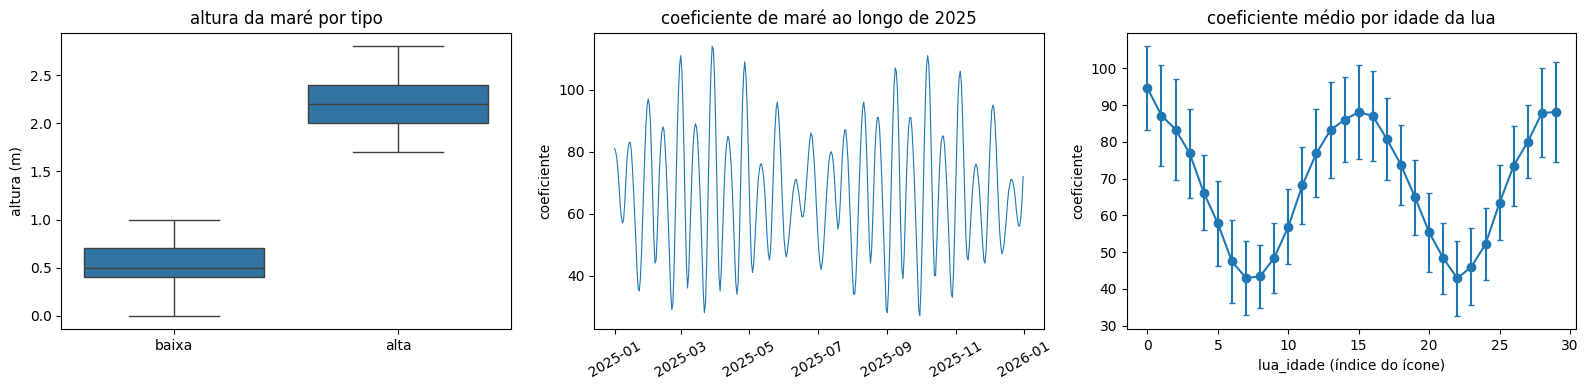

       count  mean   std  min  25%  50%  75%  max
tipo                                             
alta   705.0  2.20  0.24  1.7  2.0  2.2  2.4  2.8
baixa  705.0  0.54  0.22  0.0  0.4  0.5  0.7  1.0

coeficiente: de 27.0 a 114.0
idades com maior coeficiente médio: {0: 95.0, 29: 88.0, 15: 88.0, 28: 88.0}
idades com menor coeficiente médio: {22: 43.0, 7: 43.0, 8: 43.0, 23: 46.0}


In [6]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4))
sns.boxplot(data=mares_2025, x="tipo", y="altura_m", order=["baixa", "alta"], ax=axs[0])
axs[0].set(title="altura da maré por tipo", xlabel="", ylabel="altura (m)")

diario25 = mares_2025.groupby("data")[["coeficiente", "lua_idade"]].first().reset_index()
diario25["data"] = pd.to_datetime(diario25["data"])
axs[1].plot(diario25["data"], diario25["coeficiente"], lw=0.8)
axs[1].set(title="coeficiente de maré ao longo de 2025", ylabel="coeficiente")
axs[1].tick_params(axis="x", rotation=30)

por_lua = diario25.groupby("lua_idade")["coeficiente"].agg(["mean", "std", "count"])
axs[2].errorbar(por_lua.index, por_lua["mean"], yerr=por_lua["std"], fmt="o-", capsize=2)
axs[2].set(title="coeficiente médio por idade da lua", xlabel="lua_idade (índice do ícone)", ylabel="coeficiente")
plt.tight_layout()
plt.show()

print(mares_2025.groupby("tipo")["altura_m"].describe().round(2))
print("\ncoeficiente: de", diario25["coeficiente"].min(), "a", diario25["coeficiente"].max())
print("idades com maior coeficiente médio:", por_lua["mean"].nlargest(4).round(0).to_dict())
print("idades com menor coeficiente médio:", por_lua["mean"].nsmallest(4).round(0).to_dict())

**O que li nos gráficos de maré (2025 inteiro, 1.410 eventos):**
- **Altura:** as marés altas ficam em torno de 2,2 m (de 1,7 a 2,8) e as baixas em torno de 0,5 m (de 0,0 a 1,0). Os dois grupos não se misturam. A maré "média" fica entre eles, de 1,0 a 2,1 m.
- **Coeficiente:** varia de 27 a 114, com dois picos por mês.
- **Lua:** o coeficiente é maior na idade 0 (95) e na 15 (88) e menor na 7–8 e na 22 (43). É o esperado: a maré é mais forte na lua nova e na cheia e mais fraca nos quartos. Então `lua_idade` é mesmo a idade da lua (antes era só uma suposição minha). Isso explica também o coeficiente 96 de 10/out, dia de lua nova.

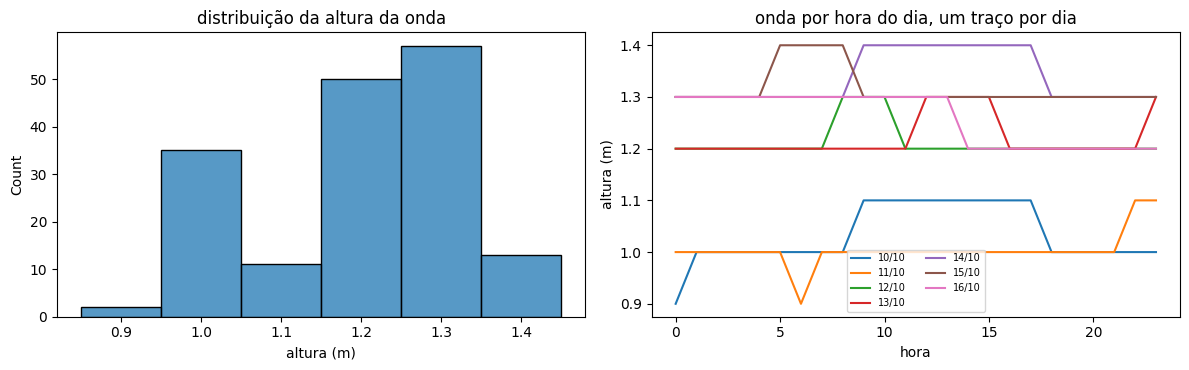

count    168.00
mean       1.20
std        0.13
min        0.90
25%        1.10
50%        1.20
75%        1.30
max        1.40
Name: valor, dtype: float64

direção da onda: {'E': 126, 'ESE': 42}
amplitude média dentro de um dia (máx - mín): 0.13 m
amplitude entre as médias diárias (máx - mín): 0.33 m


In [7]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
sns.histplot(ondas["valor"], bins=np.arange(0.85, 1.5, 0.1), ax=axs[0])
axs[0].set(title="distribuição da altura da onda", xlabel="altura (m)")
ondas["hora_dia"] = ondas["datetime"].dt.hour
ondas["dia"] = ondas["datetime"].dt.strftime("%d/%m")
sns.lineplot(data=ondas, x="hora_dia", y="valor", hue="dia", ax=axs[1], legend="brief")
axs[1].set(title="onda por hora do dia, um traço por dia", xlabel="hora", ylabel="altura (m)")
axs[1].legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

print(ondas["valor"].describe().round(2))
print("\ndireção da onda:", ondas["direcao"].value_counts().to_dict())
print("amplitude média dentro de um dia (máx - mín):", ondas.groupby("dia")["valor"].apply(lambda s: s.max() - s.min()).mean().round(2), "m")
print("amplitude entre as médias diárias (máx - mín):", ondas.groupby("dia")["valor"].mean().agg(lambda s: s.max() - s.min()).round(2), "m")

**O que li nos gráficos de onda (janela de 7 dias):**
- A onda fica entre 0,9 e 1,4 m (média 1,2 m, de 0,1 em 0,1). A direção é E (126 horas) ou ESE (42).
- Ela muda mais de um dia para o outro do que dentro do dia: no mesmo dia varia em média 0,13 m, e entre as médias dos dias a diferença é de 0,33 m. Não existe uma hora do dia com onda maior; o que muda é o dia.

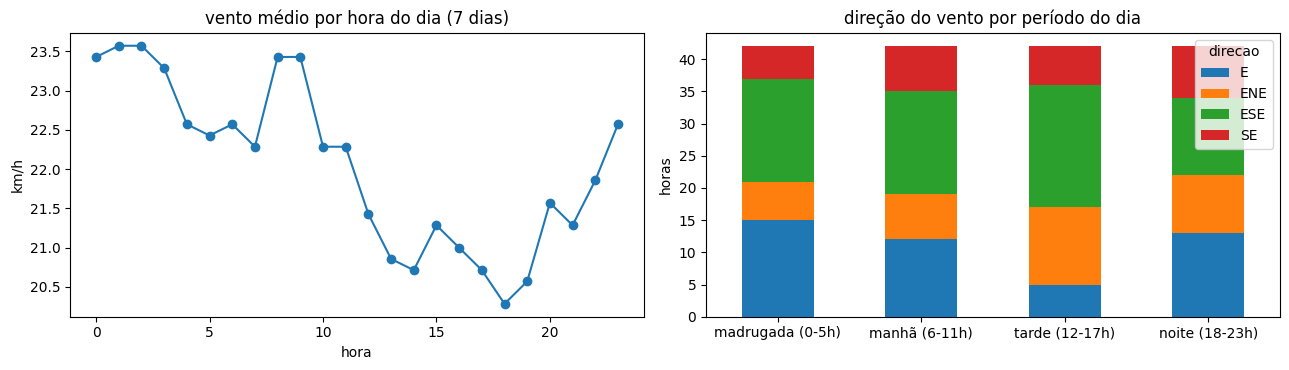

count    168.0
mean      22.1
std        2.5
min       15.0
25%       20.0
50%       22.0
75%       24.0
max       27.0
Name: valor, dtype: float64

horas mais calmas (média km/h): {18: 20.3, 19: 20.6, 14: 20.7, 17: 20.7}
horas mais ventosas (média km/h): {1: 23.6, 2: 23.6, 0: 23.4, 8: 23.4}

direção do vento: {'ESE': 63, 'E': 45, 'ENE': 34, 'SE': 26}


In [8]:
vento["hora_dia"] = vento["datetime"].dt.hour
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
vento.groupby("hora_dia")["valor"].mean().plot(ax=axs[0], marker="o")
axs[0].set(title="vento médio por hora do dia (7 dias)", xlabel="hora", ylabel="km/h")

periodo = pd.cut(vento["hora_dia"], [-1, 5, 11, 17, 23], labels=["madrugada (0-5h)", "manhã (6-11h)", "tarde (12-17h)", "noite (18-23h)"])
pd.crosstab(periodo, vento["direcao"]).plot.bar(stacked=True, ax=axs[1], rot=0)
axs[1].set(title="direção do vento por período do dia", xlabel="", ylabel="horas")
plt.tight_layout()
plt.show()

print(vento["valor"].describe().round(1))
print("\nhoras mais calmas (média km/h):", vento.groupby("hora_dia")["valor"].mean().nsmallest(4).round(1).to_dict())
print("horas mais ventosas (média km/h):", vento.groupby("hora_dia")["valor"].mean().nlargest(4).round(1).to_dict())
print("\ndireção do vento:", vento["direcao"].value_counts().to_dict())

**O que li nos gráficos de vento (janela de 7 dias):**
- O vento é mais calmo no fim da tarde (18h–19h, 20,5 km/h; também 14h e 17h, 20,7) e mais forte na madrugada (0h–2h, 23,5) e às 8h–9h (23,4). A diferença é pequena, de 3 a 4 km/h.
- A direção mais comum é ESE (63 horas), depois E (45), ENE (34) e SE (26). Muda pouco no dia: o E aparece mais de madrugada e à noite, e o ENE mais à tarde. O vento sempre vem do mar para a costa, então nenhuma hora tem vento terral.

## 4. Juntar as tabelas

Esta é a parte difícil, e ela tem mais de uma resposta certa.

As granularidades não batem: onda e vento são leituras horárias; maré são ~4
eventos por dia (os instantes de máxima e mínima). Para ter uma linha por hora
com as três informações você precisa decidir:

- Como levar a maré para a grade horária? Interpolar entre eventos? Repetir o
  último valor? Guardar apenas se a maré está subindo ou descendo? O que cada
  escolha assume sobre a curva real da maré — e onde essa suposição erra?
- Qual o tipo de junção? A previsão de onda e a de vento cobrem exatamente as
  mesmas horas? Se não, você mantém as horas incompletas ou corta?
- Que variáveis derivadas de tempo ajudam a responder a pergunta do projeto
  (dia da semana, período do dia, ...)?

Justifique as escolhas em markdown. Elas são a base das duas próximas etapas.

In [9]:

def mare_na_grade(eventos: pd.DataFrame, horas: pd.DatetimeIndex) -> pd.DataFrame:
    """Altura da maré e se está subindo, para cada instante em `horas`."""
    t_ev = eventos["datetime"].to_numpy()
    h_ev = eventos["altura_m"].to_numpy()
    alta = (eventos["tipo"] == "alta").to_numpy()

    t = horas.to_numpy()
    i = np.searchsorted(t_ev, t, side="right") - 1
    if (i < 0).any() or (i >= len(t_ev) - 1).any():
        raise ValueError("faltam eventos de maré antes/depois de alguma hora da grade")

    f = (t - t_ev[i]) / (t_ev[i + 1] - t_ev[i])
    altura = h_ev[i] + (h_ev[i + 1] - h_ev[i]) * (1 - np.cos(np.pi * f)) / 2
    return pd.DataFrame({"mare_m": altura, "mare_subindo": alta[i + 1].astype(int)}, index=horas)


meio = mares.iloc[5:-5]
teste = mare_na_grade(mares, pd.DatetimeIndex(meio["datetime"]))
print("erro máx. nos eventos (m):", np.abs(teste["mare_m"].to_numpy() - meio["altura_m"].to_numpy()).max())

erro máx. nos eventos (m): 0.0


In [10]:
diario = mares.groupby("data")[["coeficiente", "lua_idade"]].first()

base = (
    ondas[["datetime", "valor", "direcao"]].rename(columns={"valor": "onda_m", "direcao": "onda_dir"})
    .merge(
        vento[["datetime", "valor", "direcao"]].rename(columns={"valor": "vento_kmh", "direcao": "vento_dir"}),
        on="datetime", how="inner", validate="one_to_one",
    )
)
print("linhas após juntar onda + vento:", len(base), "(ondas:", len(ondas), "| vento:", len(vento), ")")

mare = mare_na_grade(mares, pd.DatetimeIndex(base["datetime"]))
dataset = base.join(mare.reset_index(drop=True))
dataset["data"] = dataset["datetime"].dt.strftime("%Y-%m-%d")
dataset["hora"] = dataset["datetime"].dt.hour
dataset = dataset.merge(diario, left_on="data", right_index=True, how="left", validate="many_to_one")
dataset.head()

linhas após juntar onda + vento: 168 (ondas: 168 | vento: 168 )


,datetime,onda_m,onda_dir,vento_kmh,vento_dir,mare_m,mare_subindo,data,hora,coeficiente,lua_idade
0,2026-10-10 00:00:00,0.9,ESE,24.0,ESE,1.219251,1,2026-10-10,0,96.0,29
1,2026-10-10 01:00:00,1.0,ESE,25.0,SE,1.814631,1,2026-10-10,1,96.0,29
2,2026-10-10 02:00:00,1.0,ESE,24.0,SE,2.306899,1,2026-10-10,2,96.0,29
3,2026-10-10 03:00:00,1.0,ESE,23.0,ESE,2.573637,1,2026-10-10,3,96.0,29
4,2026-10-10 04:00:00,1.0,ESE,22.0,ESE,2.547400,0,2026-10-10,4,96.0,29


In [11]:
print(dataset.shape, "| nulos:", dataset.isna().sum().sum(), "| dias:", dataset["data"].nunique())
print(dataset[["onda_m", "vento_kmh", "mare_m", "coeficiente"]].describe().round(2))
print("subindo:", dataset["mare_subindo"].mean().round(2), "(esperado perto de 0,5)")

(168, 11) | nulos: 0 | dias: 7
       onda_m  vento_kmh  mare_m  coeficiente
count  168.00     168.00  168.00       168.00
mean     1.20      22.05    1.40        72.57
std      0.13       2.45    0.68        19.07
min      0.90      15.00    0.21        41.00
25%      1.10      20.00    0.79        53.00
50%      1.20      22.00    1.42        76.00
75%      1.30      24.00    1.98        92.00
max      1.40      27.00    2.60        96.00
subindo: 0.51 (esperado perto de 0,5)


### Decisão de junção: o que cada escolha assume e onde erra

**O que escolhi:** interpolar a maré com uma curva de cosseno entre dois eventos e guardar também se ela está subindo ou descendo (`mare_subindo`). A maré muda devagar perto da alta e da baixa e rápido no meio, e o cosseno imita isso. Uma interpolação linear faria a maré andar sempre na mesma velocidade.

| Alternativa | O que assume | Onde erra |
|---|---|---|
| Repetir o último valor | A maré fica parada até o próximo evento | Cria degraus de até ~2 m e esconde se ela está enchendo ou secando |
| Só subindo ou descendo | Só o sentido importa | Perde a altura, que pesa na quebra da onda |
| Interpolação linear | A maré varia sempre na mesma velocidade | Exagera a variação perto da alta e da baixa |
| **Cosseno (a que usei)** | A maré é uma curva suave entre dois extremos | Erra quando a maré real é assimétrica (aqui o intervalo entre eventos vai de 6,0 h a 7,2 h) e quando vento e pressão mexem na altura, o que a tábua não traz |

O teste "erro máximo = 0" só mostra que a função devolve a altura da tábua nos próprios eventos. Ele não prova que a curva entre eles está certa, porque não tenho a altura hora a hora para comparar.

**Junção:** `inner join` por `datetime`. Onda e vento têm as mesmas 168 horas, então não perdi nenhuma. A maré é calculada para essas horas a partir dos eventos de agosto a outubro. Coeficiente e lua valem para o dia todo e se repetem nas 24 linhas.

**Limitação:** o dataset final tem só 168 linhas (7 dias), porque a previsão de onda e vento cobre uma semana. Isso limita o ML e a resposta de "quando voltar": dá para dizer qual hora desta semana é melhor, mas não qual mês do ano.

## 5. Visualizações voltadas à pergunta

Agora com a tabela junta: quando as condições coincidem?

- As horas de onda maior são as mesmas de vento mais fraco, ou elas se
  desencontram?
- Existe relação visível entre altura da maré e altura da onda?
- Quais dias e horas da janela se destacam?

Prefira poucos gráficos legíveis a muitos gráficos.

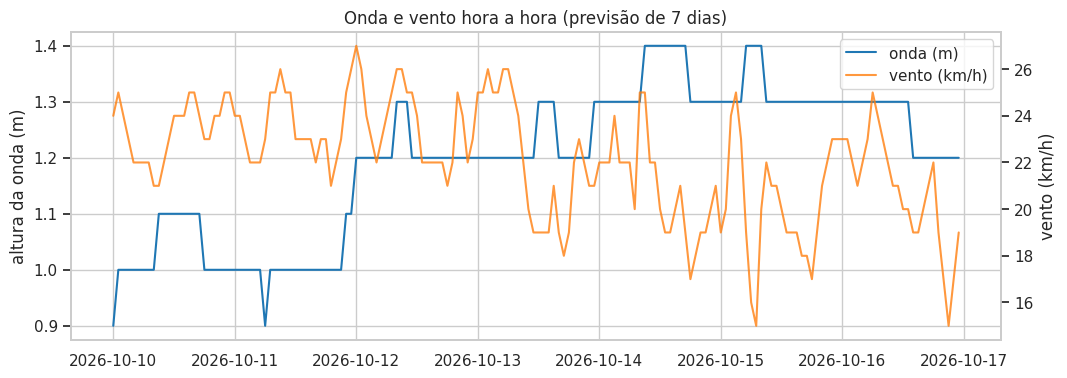

correlação onda x vento: -0.41


In [12]:
sns.set_theme(style="whitegrid")
fig, ax1 = plt.subplots(figsize=(12, 4))
ax2 = ax1.twinx()
ax1.plot(dataset["datetime"], dataset["onda_m"], color="tab:blue", label="onda (m)")
ax2.plot(dataset["datetime"], dataset["vento_kmh"], color="tab:orange", label="vento (km/h)", alpha=0.8)
ax1.set(ylabel="altura da onda (m)", title="Onda e vento hora a hora (previsão de 7 dias)")
ax2.set_ylabel("vento (km/h)")
ax2.grid(False)
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.88))
plt.show()
print("correlação onda x vento:", dataset["onda_m"].corr(dataset["vento_kmh"]).round(2))

**O que li no gráfico 1:** a onda sobe ao longo da semana (1,0 m em 10 e 11/out, 1,3–1,4 m em 14–16/out) e o vento cai de 23,5 para 20 km/h. As curvas andam em sentidos opostos (correlação −0,41): dia de onda maior tende a ter vento mais fraco, o que é bom para surfar. Mas isso vale por dia, não por hora. Dentro de um mesmo dia a onda quase não muda.

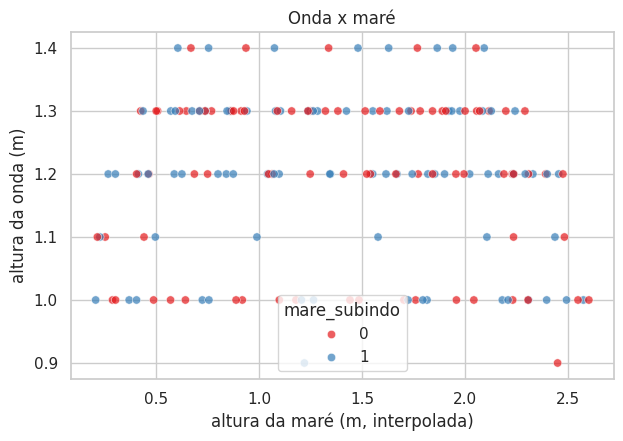

correlação onda x maré: -0.07
correlação onda x coeficiente: -0.74 | valores distintos de coeficiente: 7


In [13]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.scatterplot(data=dataset, x="mare_m", y="onda_m", hue="mare_subindo", palette="Set1", alpha=0.7, ax=ax)
ax.set(xlabel="altura da maré (m, interpolada)", ylabel="altura da onda (m)",
       title="Onda x maré")
plt.show()
print("correlação onda x maré:", dataset["onda_m"].corr(dataset["mare_m"]).round(2))
print("correlação onda x coeficiente:", dataset["onda_m"].corr(dataset["coeficiente"]).round(2),
      "| valores distintos de coeficiente:", dataset["coeficiente"].nunique())

**O que li no gráfico 2:** a nuvem de pontos é plana. Onda de 1,0 a 1,4 m aparece com maré baixa e alta, subindo ou descendo (correlação −0,07). Nesta semana a onda não depende da maré. Isso não quer dizer que a maré não importe para surfar, só que a previsão de altura da onda do site não depende dela.

**Cuidado com o coeficiente:** a correlação onda × coeficiente dá −0,74, mas o coeficiente tem um valor por dia, ou seja, 7 valores. Os dois mudam sempre no mesmo sentido na semana (o coeficiente cai e a onda sobe). Uma tendência em comum entre 7 pontos não prova relação, então não uso isso como evidência.

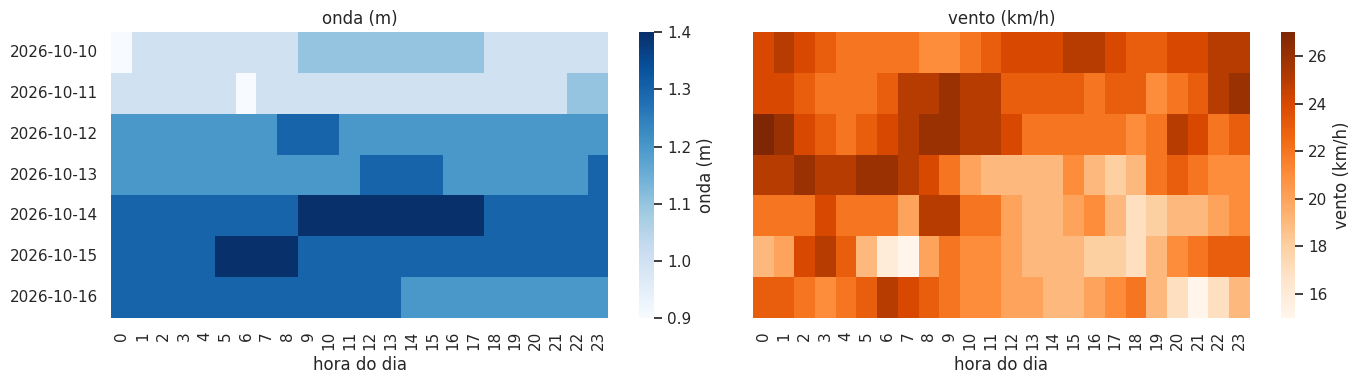

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, col, cmap, titulo in [(axs[0], "onda_m", "Blues", "onda (m)"), (axs[1], "vento_kmh", "Oranges", "vento (km/h)")]:
    tab = dataset.pivot(index="data", columns="hora", values=col)
    sns.heatmap(tab, cmap=cmap, ax=ax, cbar_kws={"label": titulo})
    ax.set(title=titulo, xlabel="hora do dia", ylabel="")
plt.tight_layout()
plt.show()

**O que li no gráfico 3:** 14 e 15/out se destacam. Em 14/out a onda fica em 1,4 m das 09h às 17h (com vento de 25 a 19 km/h). Em 15/out ela chega a 1,4 m às 05h–08h, e às 06h–07h o vento cai para 15–16 km/h, o mínimo da semana: é o melhor encontro de onda alta com vento fraco. 10 e 11/out têm as ondas mais baixas (1,0 m). O vento é mais fraco no fim da tarde (20 km/h às 17h–19h) e mais forte de madrugada (23,5), mas a diferença entre horas é pequena. A variação entre os dias é maior que a variação entre as horas do mesmo dia.

**Direção do vento:** nas 168 horas ele vem de ENE, E, ESE ou SE, ou seja, do mar para a costa. (Estou supondo que o site indica de onde o vento vem; a costa de João Pessoa olha para o leste.) Não há vento terral em nenhuma hora, e isso conta na regra de label.

## 6. Salvar o dataset processado

Grave o resultado em `../data/processed/dataset.csv`. A Etapa 3 lê esse
arquivo — se as colunas mudarem depois, o notebook de ML muda também.

In [15]:
colunas = ["datetime", "data", "hora", "onda_m", "onda_dir", "vento_kmh", "vento_dir",
           "mare_m", "mare_subindo", "coeficiente", "lua_idade"]
dataset[colunas].to_csv(DIR_PROC / "dataset.csv", index=False)
print(len(dataset), "linhas salvas em", DIR_PROC / "dataset.csv")

168 linhas salvas em ../data/processed/dataset.csv


## 7. Conclusões

Em texto, sem código:

1. O que os dados mostram sobre as condições da janela coletada?
2. Que decisão de limpeza ou de junção você tomou que mais influencia o
   resultado, e por quê?
3. O que esses dados **não** permitem afirmar?

### Conclusões da Etapa 2

**1. O que os dados mostram.** Na semana de 10 a 16/out a onda cresce (1,0 m para 1,3–1,4 m) e o vento enfraquece (23,5 para 20 km/h). O melhor encontro é em 14 e 15/out, principalmente 15/out às 06h–07h. A onda muda mais de um dia para o outro do que dentro do dia, e não depende da maré. O vento é sempre do mar para a costa.

**2. A decisão que mais pesa.** Levar a maré (4 eventos por dia) para a grade de horas por interpolação com cosseno. Ela assume uma curva suave entre alta e baixa e erra quando a maré real é assimétrica, principalmente nos intervalos longos (11/out às 04:59).

**3. O que não dá para afirmar.** Nada fora desta semana (168 linhas, uns 7 dias independentes), nem que a previsão do site vai se confirmar no mar. Também não dá para dizer qual maré é boa para surfar, nem se o coeficiente influencia a onda (só 7 valores na semana).